In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un método sistemático para dibujar el grafo PERT consiste en dar a cada actividad su propio nodo de inicio y de fin y unir con una ficticia cada prelación. El resultado es correcto, pero tiene muchas más ficticias de las necesarias. Considere el cuadro de prelaciones adjunto.

In [3]:
pregunta_1 = "1. Dibuje el grafo PERT por el método sistemático (sin fusionar nodos). ¿Cuántas ficticias tiene?  "
pregunta_2 = "2. Simplifíquelo: una ficticia puede eliminarse fusionando sus dos nodos cuando al hacerlo no se crea ninguna prelación nueva ni desaparece ninguna, no se juntan dos arcos entre los mismos nodos y el grafo sigue teniendo un único origen y un único final. ¿Cuántas ficticias quedan?  "
pregunta_3 = "3. Compruebe que ambos grafos tienen el mismo cuadro de ancestros y las mismas rutas (sin ficticias).  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT por el método sistemático (sin fusionar nodos). ¿Cuántas ficticias tiene?  

2. Simplifíquelo: una ficticia puede eliminarse fusionando sus dos nodos cuando al hacerlo no se crea ninguna prelación nueva ni desaparece ninguna, no se juntan dos arcos entre los mismos nodos y el grafo sigue teniendo un único origen y un único final. ¿Cuántas ficticias quedan?  

3. Compruebe que ambos grafos tienen el mismo cuadro de ancestros y las mismas rutas (sin ficticias).  

In [4]:
#| tbl-cap: "Cuadro de prelaciones del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,C'      ),
    ('E'     , 'B'        ),
    ('F'     , 'D,E'      ),
    ('G'     , 'F'        ),
    ('H'     , 'F'        ),
    ('I'     , 'G,H'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,C"
E,B
F,"D,E"
G,F
H,F
I,"G,H"


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT por el método sistemático (sin fusionar nodos). ¿Cuántas ficticias tiene?  

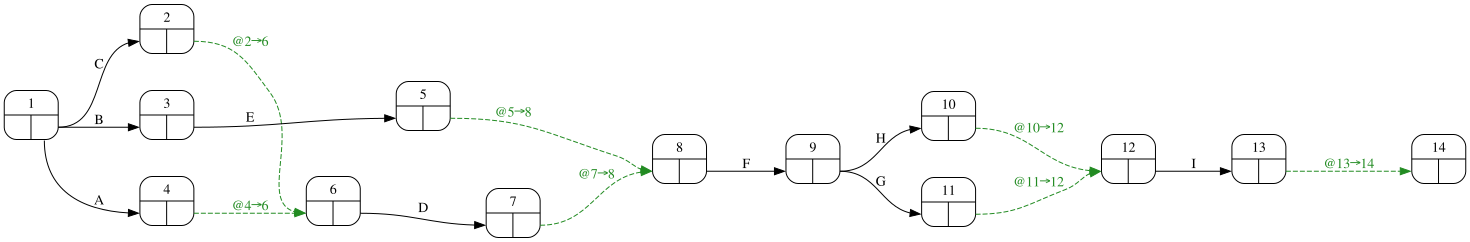

In [7]:
#| fig-cap: "Grafo PERT sin simplificar"
#| label: fig-pertSinSimplificar
proyecto_bruto = prelaciones.create_project(simplify=False)
proyecto_bruto.pert(durations=False, ranksep=1)

In [8]:
Markdown(f'El grafo sin simplificar tiene {len(proyecto_bruto.nodes)} nodos y {len(proyecto_bruto.dummies)} ficticias: {", ".join(proyecto_bruto.dummies)}.')

El grafo sin simplificar tiene 14 nodos y 7 ficticias: @10→12, @11→12, @13→14, @2→6, @4→6, @5→8, @7→8.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Simplifíquelo: una ficticia puede eliminarse fusionando sus dos nodos cuando al hacerlo no se crea ninguna prelación nueva ni desaparece ninguna, no se juntan dos arcos entre los mismos nodos y el grafo sigue teniendo un único origen y un único final. ¿Cuántas ficticias quedan?  

La librería aplica exactamente esas reglas (`simplify`): recorre las ficticias y contrae las que pueden contraerse sin alterar las prelaciones distantes ni la estructura.

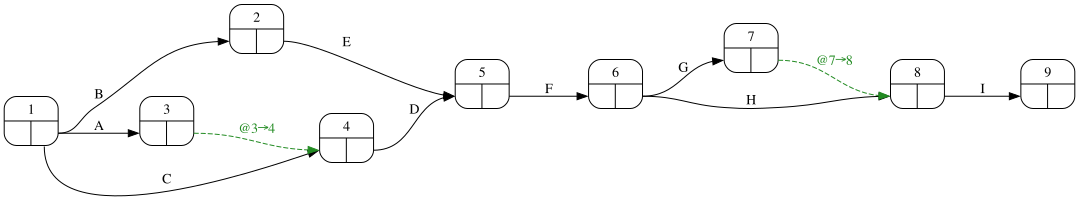

In [10]:
#| fig-cap: "Grafo PERT simplificado"
#| label: fig-pertSimplificado
proyecto = prelaciones.create_project()
proyecto.pert(durations=False, ranksep=1)

In [11]:
Markdown(f'Tras simplificar quedan {len(proyecto.nodes)} nodos y {len(proyecto.dummies)} ficticias: {", ".join(proyecto.dummies) or "ninguna"}. '
         f'Se han eliminado {len(proyecto_bruto.dummies) - len(proyecto.dummies)}.')

Tras simplificar quedan 9 nodos y 2 ficticias: @3→4, @7→8. Se han eliminado 5.

Las ficticias que quedan son las que transmiten una prelación que no puede expresarse compartiendo nodos: cada una une el final de un grupo de actividades con el inicio de otro grupo que depende de ellas *y de otras más*.

## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Compruebe que ambos grafos tienen el mismo cuadro de ancestros y las mismas rutas (sin ficticias).  

In [13]:
mismo_ancestros = proyecto.distant_predecessor() == proyecto_bruto.distant_predecessor()
rutas = {' - '.join(a) for a in proyecto.paths(dummies=False).values()}
rutas_bruto = {' - '.join(a) for a in proyecto_bruto.paths(dummies=False).values()}
print('Mismo cuadro de ancestros:', mismo_ancestros)
print('Mismas rutas:', rutas == rutas_bruto, f'({len(rutas)} rutas)')

Mismo cuadro de ancestros: True
Mismas rutas: True (6 rutas)
